# 02 · Preprocessing and train/test splits

**Learning objectives**

1. Turn an event log into a weighted, sparse **user × item matrix**, and explain each step.
2. Use **k-core filtering** and understand its trade-off.
3. Explain why recommenders must be evaluated with a **temporal split**, and *measure* how much a random split inflates the results.
4. Quantify **cold start**: who and what we cannot score.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recsys import config
from recsys.data import load_or_synthesize
from recsys.preprocess import (IdMapper, add_weights, build_interaction_matrix, clean_events,
                               filter_outlier_users, k_core_filter)
from recsys.split import temporal_split, random_split, build_ground_truth
from recsys.plotting import set_style, PALETTE, MUTED

set_style()
events, item_categories, SOURCE = load_or_synthesize()

  USING SYNTHETIC DATA: data/raw/events.csv was not found.
  The numbers below come from a simulator, NOT from RetailRocket.
  Run `make data` (needs a Kaggle API token) to use the real dataset.


## 1. Clean, then weight events by how much they tell us

Not all behaviour is equal evidence of interest. We map each event type to a **weight**:

In [2]:
config.EVENT_WEIGHTS

{'view': 1.0, 'addtocart': 4.0, 'transaction': 8.0}

These numbers are a **modelling decision**, not a law. A useful sanity check is the funnel: if roughly 1 in 30 views leads to a cart, a cart is "worth" more than a view. But a cart is not worth 30 views, because views also capture browsing intent the cart misses. Exercise 1 asks you to tune them.

In [3]:
ev = add_weights(clean_events(events))
ev, bots = filter_outlier_users(ev, config.MAX_USER_EVENTS)
print(f"removed {len(bots)} bot-like users; {len(ev):,} events remain")
ev.head()

removed 15 bot-like users; 41,200 events remain


,timestamp,visitorid,event,itemid,transactionid,weight
0,2015-05-03 00:09:44.663,2608,view,5592,NaN,1.0
1,2015-05-03 00:10:48.095,2608,view,11413,NaN,1.0
2,2015-05-03 00:11:41.062,2608,view,8885,NaN,1.0
3,2015-05-03 00:13:07.339,2608,view,11668,NaN,1.0
4,2015-05-03 00:13:49.496,14954,view,7427,NaN,1.0


## 2. Split by time

The model will be trained on the past and used on the future, so we evaluate it that way: **train = everything before the cutoff, test = the last `TEST_DAYS` days.**

```
 ───────────────── train ─────────────────┃──── test (7 days) ────▶ time
                                      cutoff
```

In [4]:
split = temporal_split(ev, test_days=config.TEST_DAYS)
print(f"cutoff: {split.cutoff}")
print(f"train events: {len(split.train):,}   test events: {len(split.test):,}")

cutoff: 2015-06-24 23:54:26.254000
train events: 36,113   test events: 5,087


## 3. k-core filtering (training data only)

A user with one interaction teaches collaborative filtering almost nothing, and the same goes for an item one person ever touched. The **k-core** keeps only users with ≥ k distinct items *and* items with ≥ k distinct users. Removing items can push users below the threshold, so it is **iterative**.

> **Principal DS note.** Filter the **training** period only. If you k-core the whole log before splitting, you use *test-period* activity to decide who is in training. That is a subtle form of leakage.

In [5]:
rows = []
for k in [1, 2, 3, 5, 10]:
    core = k_core_filter(split.train, k, k)
    rows.append({"k": k, "users": core["visitorid"].nunique(), "items": core["itemid"].nunique(),
                 "events": len(core), "share of events kept": len(core) / len(split.train)})
kcore = pd.DataFrame(rows).set_index("k")
kcore["share of events kept"] = kcore["share of events kept"].map("{:.1%}".format)
kcore

,users,items,events,share of events kept
k,,,,
1,2830,1240,36113,100.0%
2,2519,1032,35172,97.4%
3,2149,889,33350,92.3%
5,1474,656,28474,78.8%
10,453,254,13982,38.7%


Larger k gives a denser matrix and easier learning, but fewer users and items we can serve. We use `k = 2`: it removes the one-off noise and keeps as much of the catalogue as possible.

In [6]:
train = k_core_filter(split.train, config.MIN_USER_ITEMS, config.MIN_ITEM_USERS)

## 4. Build the sparse matrix

Models work with integer indices `0..n-1`, not raw ids. `IdMapper` handles the translation both ways. Repeated events on the same (user, item) pair are **summed** and then **log-transformed** (`log1p`), so the 50th view adds less than the 2nd.

X: 2,519 users × 1,032 items, 20,345 non-zeros, density 0.7826%, 0.1 MB of values


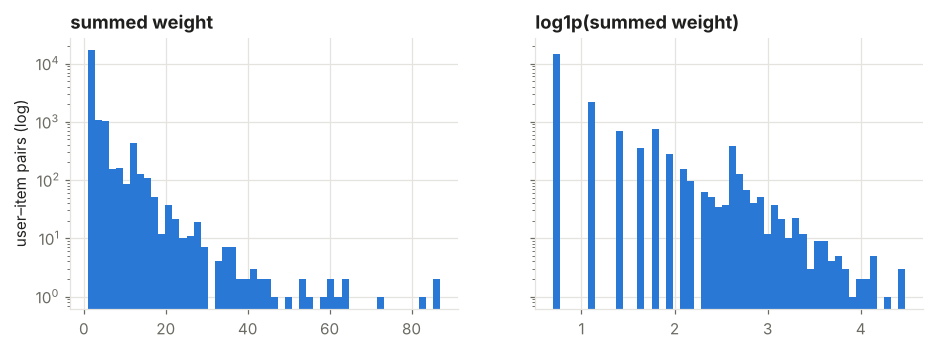

In [7]:
user_map, item_map = IdMapper(train["visitorid"]), IdMapper(train["itemid"])
X_raw = build_interaction_matrix(train, user_map, item_map, transform="none")
X = build_interaction_matrix(train, user_map, item_map, transform="log1p")
print(f"X: {X.shape[0]:,} users × {X.shape[1]:,} items, {X.nnz:,} non-zeros, "
      f"density {X.nnz / np.prod(X.shape):.4%}, {X.data.nbytes / 1e6:.1f} MB of values")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
axes[0].hist(X_raw.data, bins=50, color=PALETTE[0]); axes[0].set_title("summed weight"); axes[0].set_yscale("log")
axes[1].hist(X.data, bins=50, color=PALETTE[0]); axes[1].set_title("log1p(summed weight)")
axes[0].set_ylabel("user–item pairs (log)")
plt.show()

## 5. Ground truth and cold start

For each test-period user we already know, the **relevant items** are the items they interacted with in the test week that they had *not* interacted with in training. (We never re-recommend seen items, so it would be unfair to score models on them.)

In [8]:
gt = build_ground_truth(split.test, user_map, item_map, train_matrix=X)
pd.Series(gt.stats)

test_users                927
cold_users                198
test_events              5087
events_with_cold_item     192
pairs_already_seen        912
eval_users                627
dtype: int64

Read `cold_users` carefully. On RetailRocket, **most test-week visitors are new**. Collaborative filtering cannot help them at all, which makes the non-personalised fallback a first-class part of the product, not an afterthought.

Also look at `pairs_already_seen`: a large share of next-week activity is users coming back to items they already know.

## 6. Why not a random split? Let's measure it

Many tutorials split rows at random. Let's compare the two protocols with two simple models. If the random split gives higher numbers, those numbers are **optimistic**: the model saw "future" interactions (including future popularity) during training.

In [9]:
from recsys.models import PopularityRecommender, ItemKNNRecommender
from recsys.metrics import evaluate


def run_protocol(train_events, test_events):
    tr = k_core_filter(train_events, config.MIN_USER_ITEMS, config.MIN_ITEM_USERS)
    um, im = IdMapper(tr["visitorid"]), IdMapper(tr["itemid"])
    Xp = build_interaction_matrix(tr, um, im)
    g = build_ground_truth(test_events, um, im, train_matrix=Xp)
    out = {name: evaluate(m.fit(Xp), Xp, g)["ndcg@10"]
           for name, m in {"popularity": PopularityRecommender(), "item_knn": ItemKNNRecommender()}.items()}
    out["eval users"] = len(g)
    return out


test_share = len(split.test) / len(ev)
rand_train, rand_test = random_split(ev, test_frac=test_share)
comparison = pd.DataFrame({
    "temporal split (honest)": run_protocol(split.train, split.test),
    "random split (leaky)": run_protocol(rand_train, rand_test),
}).T
comparison

,popularity,item_knn,eval users
temporal split (honest),0.066352,0.192926,627.0
random split (leaky),0.033567,0.227607,1211.0


Read the table carefully. The two protocols disagree, and not always in the same direction:

* **Item-kNN usually looks better** under the random split. Co-views from the "test" weeks are in its training data, so it has literally seen which items go together in the future.
* **Popularity can look better *or* worse.** Under the random split, "popular" is averaged over the whole period, including the test weeks. That helps if demand is stable and hurts if items trend up and down.
* The **evaluation population differs** too: random splits put almost every user in both train and test, so cold start disappears.

The point is not "random is always higher". The point is that a random split measures a situation that never happens in production, so its numbers cannot tell you how the model will perform there, nor reliably which model will win. **Always split by time.**

## 7. Wrapping it up: `prepare_data`

From now on, one call does all of the above in the right order, so that every model is compared on identical data:

In [10]:
from recsys.pipeline import prepare_data

data = prepare_data(events)
data.summary()

train users                                                   2519
train items                                                   1032
train interactions (user-item pairs)                         20345
matrix density                                            0.78262%
cutoff                                  2015-06-24 23:54:26.254000
raw events                                                   71281
bot users removed                                               15
train events (after k-core)                                  35172
test events                                                   5087
test: test_users                                               927
test: cold_users                                               198
test: test_events                                             5087
test: events_with_cold_item                                    192
test: pairs_already_seen                                       912
test: eval_users                                              

## Key takeaways

* Weight events by strength, sum repeats, and log-transform for diminishing returns.
* k-core **only the training period**.
* Split **by time**. Random splits leak the future and inflate metrics.
* Cold start is the *majority* case on real e-commerce traffic, so plan a fallback.

## Exercises

1. **(Easy)** Re-run `prepare_data` with `transform="binary"`. How do the matrix statistics change? (You will measure the effect on accuracy in notebook 03.)
2. **(Medium)** Try event weights `{"view": 1, "addtocart": 10, "transaction": 30}`. Which notebook-03 metric would you expect to move most, and why?
3. **(Medium)** Implement a *rolling-origin* evaluation: three consecutive 7-day test windows, each trained on everything before it. How stable is a model's NDCG across windows?
4. **(Stretch)** Compare `leave_last_out` with `temporal_split`. Build a case where one user's held-out event comes *before* another user's training event, and explain why that matters.